# **Project** | Analyzing Website Performance for The Grammys

<div style="text-align: center;">
<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/3/36/RA_lockup_stacked_black.svg/3840px-RA_lockup_stacked_black.svg.png" alt="The Recording Academy Logo" width="320"/>
</div>
<br>

# **Katriel Layam**
**Introduction** 

The VP of Digital Strategy, Ray Starck, decided in 2022 to split the websites into [www.grammy.com](https://grammy.com) and [www.recordingacademy.com](https://recordingacademy.com) to better serve the Recording Academy's various audience needs. For this project, I will examine the impact of splitting up the two websites, and analyze the data for a better understanding of trends and audience behavior.


## Data Dictionary
I'll be working with two files, `grammys_live_web_analytics.csv` and `ra_live_web_analytics.csv`.

These files will contain the following information:

- **date** - The date the data was confirmed. It is in `yyyy-mm-dd` format.
- **visitors** - The number of users who went on the website on that day.
- **pageviews** - The number of pages that all users viewed on the website.
- **sessions** - The total number of sessions on the website. A session is a group of user interactions with your website that take place within a given time frame. For example a single session can contain multiple page views, events, social interactions.
- **bounced_sessions** - The total number of bounced sessions on the website. A bounced session is when a visitor comes to the website and does not interact with any pages / links and leaves.
- **avg_session_duration_secs** - The average length for all session durations for all users that came to the website that day.
- **awards_week** - A binary flag if the dates align with marketing campaigns before and after the Grammys award ceremony was held. This is the big marketing push to get as many eyeballs watching the event.
- **awards_night** - The actual night that Grammy Awards event was held.

# **Part 1** - Exploring the Data
I'll be exploring the dataset first so that I will be better equipped to make meaningful observations and informed decisions in the future. 


## Step 1

Import both the `pandas` and `plotly.express` libraries to load the data into a DataFrame and visualize.


In [1]:
# Import libraries
import pandas as pd 
import plotly.express as px 

## Step 2

Load in the first two files for analysis, which are the `grammy_live_web_analytics.csv` and `ra_live_web_analytics.csv`.


**A.** Read the `grammy_live_web_analytics.csv` file. Stored the data in a DataFrame named `full_df`.

**B.** Read the `ra_live_web_analytics.csv` file. Stored that data into a DataFrame called `rec_academy`.

**C.** Preview both DataFrames to get familiarized with the data. 

In [2]:
# Read in data
full_df = pd.read_csv('datasets/grammy_live_web_analytics.csv')

rec_academy = pd.read_csv('datasets/ra_live_web_analytics.csv')

In [3]:
# Preview full_df dataframe
display(full_df.head())

,date,visitors,pageviews,sessions,bounced_sessions,avg_session_duration_secs,awards_week,awards_night
0,2017-01-01,9611,21407,10196,6490,86,0,0
1,2017-01-02,10752,25658,11350,7055,100,0,0
2,2017-01-03,11425,27062,12215,7569,92,0,0
3,2017-01-04,13098,29189,13852,8929,90,0,0
4,2017-01-05,12234,28288,12990,8105,95,0,0


In [4]:
# Preview rec_academy dataframe
display(rec_academy.head())

,date,visitors,pageviews,sessions,bounced_sessions,avg_session_duration_secs,awards_week,awards_night
0,2022-02-01,928,2856,1092,591,148,0,0
1,2022-02-02,1329,3233,1490,923,90,0,0
2,2022-02-03,1138,3340,1322,754,127,0,0
3,2022-02-04,811,2552,963,534,142,0,0
4,2022-02-05,541,1530,602,326,111,0,0


## Step 3

The Grammy Awards are among the most prominent events in the global music industry. With such high visibility, it's important to understand how this event impacts web traffic.

**A.** Created a line chart of the number of users on the site for every day in the `full_df`.

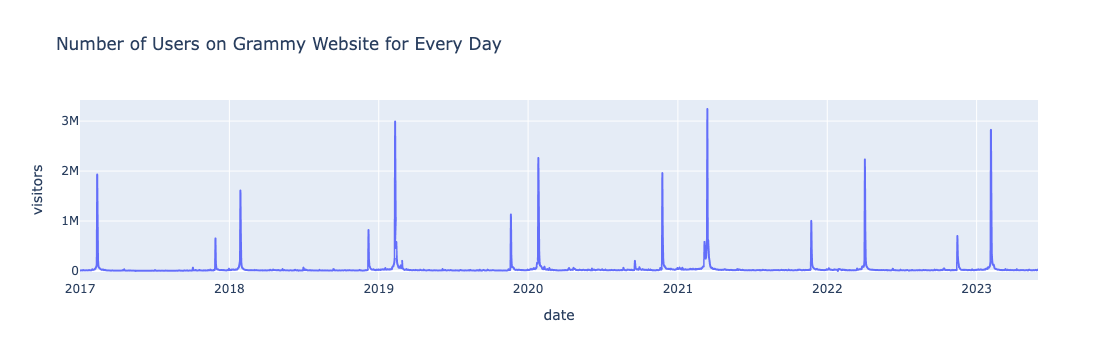

In [7]:
# Plot a line chart of the visitors on the site
px.line(full_df, 
       x = 'date', 
       y = 'visitors', 
       title = 'Number of Users on Grammy Website for Every Day')

**B.** Observations from line chart

Based on my line chart, I notice that traffic spikes occur about 2 times a year. Specifically, there seems to be a spike usually at the start of the year (ranging from January to April) and the other at the end of the year (during November or December). The spike that occurs at the start of each year is the biggest amount of traffic the website experiences while the spike at the end of the year is quite smaller. These traffic spikes align with 'Show Night' in which Grammy nominations are usually announced towards the end of the year and the Grammy ceremony occuring at the start. There are no lesser-known events that might have caused these significant increases. Besides these 2 spikes each year, website traffic is considerably low throughout the rest of the year. 

## Step 4

To evaluate the impact of the Grammy Awards on user engagement, I compared average site traffic on the day of the ceremony versus all other days.

Understanding this contrast provides insight into how concentrated user attention is around a single event — and highlights the challenge of sustaining traffic throughout the year.


**A.** Compared the average daily website visitors on days when an award ceremony was held to those when no awards ceremonies were held.

In [12]:
# Average number of visitors on awards nights versus other nights
full_df.groupby('awards_night')['visitors'].mean()

awards_night
0    3.238828e+04
1    1.389590e+06
Name: visitors, dtype: float64

**B.** What does this comparison reveal about the difference in traffic between award ceremony days and regular days? How many more visitors does the Grammy Awards site receive on Show Night?


The difference in traffic between award ceremony days and regular days is very significant. The average number of visitros on awards night is approximately 1,389,590 while on other days it is approximately 32,388. This is about a 1.35 million difference in website visitors, showing how the Recording Academy may be heavily reliant on the success of the Grammy Awards since it brings in so many users. Although this is a big event and gets a lot of traction, it is also important for the Recording Academy to maintain users year round. 

## Step 5

When The Recording Academy split its digital presence across two domains, grammy.com and recordingacademy.com, the data capture for grammy.com was not affected. Meaning, the way visitor data was collected for grammy.com stayed exactly the same before and after the split. I needed to separate the data from before the split (when both sites were combined) and after the split (when grammy.com data continued independently). The split happened on February 1, 2022 (`2022-02-01`).


Created two new DataFrames:

1. `combined_site` should contain all data with dates before `2022-02-01`.

2. `grammys` should contain all data with dates on or after `2022-02-01`.

In [13]:
# Split the data to separate the full_df into two new dataframes
# One for before the switch of the websites and one for after

combined_site = full_df[full_df['date'] < '2022-02-01']
grammys = full_df[full_df['date'] >= '2022-02-01']

In [14]:
# Run the following cell - DO NOT MODIFY
# .copy() prevents pandas from printing a warning message
combined_site = combined_site.copy()
grammys = grammys.copy()

In [16]:
# Print the shape of the combined_site dataframe
display(combined_site.shape)

(1857, 8)

# **Part 2** - Analyzing Key Metrics

The overall goal of this Project is: to analyze whether splitting the website into two has improved user engagement. This part will focus on evaluating key metrics, such as bounce rate, pages per session, and average time on site, to determine if the split has had a positive or negative impact on how visitors interact with the site.

## Step 6

I calculated the `pages_per_session` metric — the average number of unique pages a user views before leaving the site. Which is a strong indicator of engagement. 

**A.** Created a new list called `frames` containing each of my DataFrames. 

In [17]:
# Create the `frames` list containing all 3 dataframes
frames = [combined_site, rec_academy, grammys]

**B.** Added a new column called `pages_per_session` to each DataFrame, representing the average number of pageviews per session for each day.


In [19]:
# Create the `pages_per_session` column for all 3 dataframes
for frame in frames: 
    frame['pages_per_session'] = frame['pageviews'] / frame['sessions']

**C.** Visualized this new `pages_per_session` metric using a line chart for each site. 

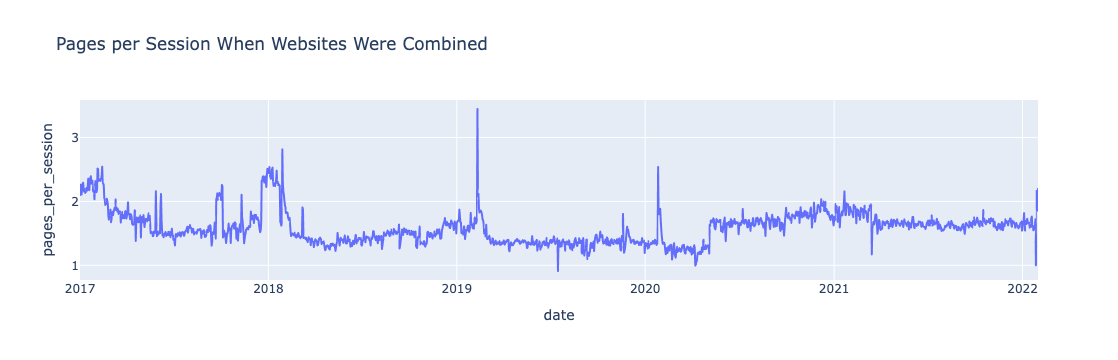

In [21]:
# combined_site graph
px.line(combined_site, 
       x = 'date', 
       y = 'pages_per_session', 
       title = 'Pages per Session When Websites Were Combined')

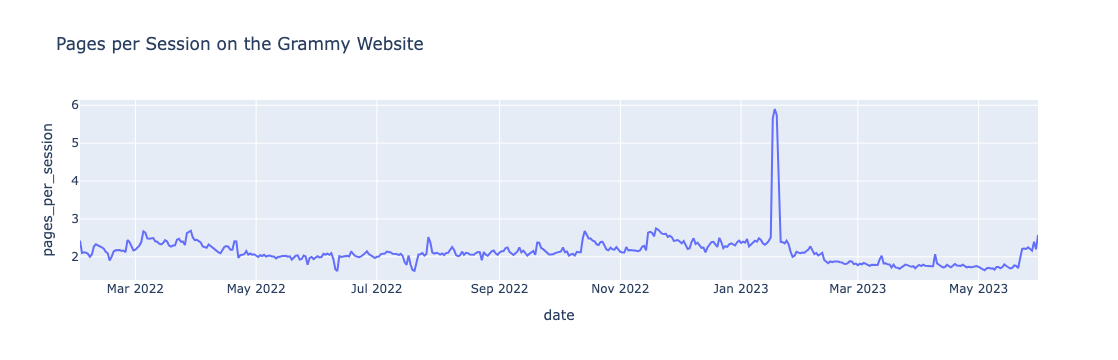

In [23]:
# grammys graph
px.line(grammys, 
       x = 'date', 
       y = 'pages_per_session', 
       title = 'Pages per Session on the Grammy Website')

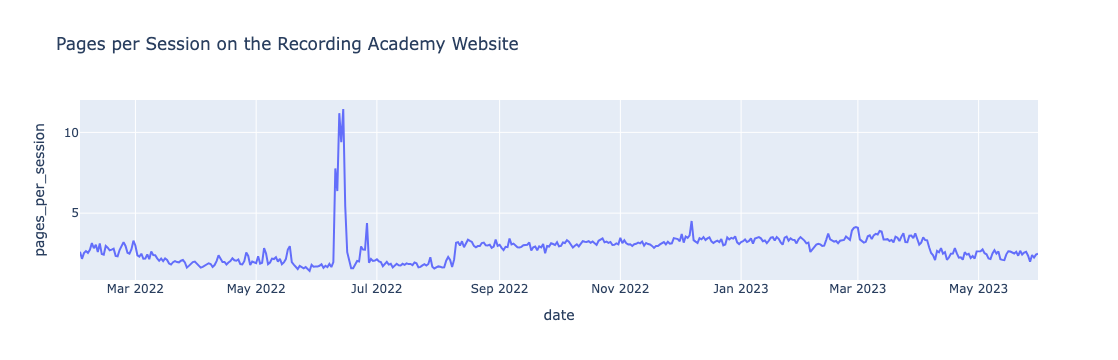

In [24]:
# rec_academy graph
px.line(rec_academy, 
       x = 'date', 
       y = 'pages_per_session', 
       title = 'Pages per Session on the Recording Academy Website')

**D.** `pages_per_session` metric and the impact of the website split. 

The pages_per_session measures the average number of unique pages a user views before leaving the site, this metric and its visualization can help indicate if the website split helped with increasing user engagement, show if certain websites have more traffic, and better understand if each website potentially caters to different audiences or for different purposes. 

## Step 7

I calculated the `bounce_rate` metric by dividing the total `bounced_sessions` by the total number of `sessions`. Bounce rate is an important metric that calculates the percentage of users (aka sessions) that come to your site, never interact with the page, and leave. They are said to have "bounced" off your home page. It is a measure of how engaging your home page is with users.

**A.** Created a function called `bounce_rate` that:

1. Takes in a `dataframe` as input
2. adds up all of the values in the `bounced_sessions` column and stores in a variable called `sum_bounced`
3. adds up all of the values in the `sessions` column and stores it in a variable called `sum_sessions`
4. returns `100 * sum_bounced / sum_sessions`


In [29]:
def bounce_rate(dataframe):
    '''
    Calculates the bounce rate for visitors on the website.
    input: dataframe with bounced_sessions and sessions columns
    output: numeric value from bounce rate
    '''

    # WRITE YOUR CODE HERE
    # Remember, the input for the function is called `dataframe`
    # All calculations must reference that variable.
    sum_bounced = dataframe['bounced_sessions'].sum() 
    sum_sessions = dataframe['sessions'].sum()
    
    bounce_rate = 100 * sum_bounced/sum_sessions
    return bounce_rate

**B.** Used the `frames` variable from Task 6 to loop over each website (represented by a dataframe) to calculate the bounce rate. Then, printed the bounce rate for each site.

In [42]:
# Calculate the Bounce Rate for each site
for frame in frames: 
    rate = bounce_rate(frame)
    print(f'{rate:.2f}%')

41.58%
33.67%
40.16%


**C.** Next, I calculated the `average_time_on_site` metric. I did this by calculating the average of the `avg_session_duration_secs` column. Average Time on Site measures how engaging your website experience is for your users. The higher the number, the longer they are staying on your page and engaging with the content.


In [44]:
# Calculate the average of the avg_session_duration_secs
for frame in frames: 
    average_time_on_site = frame['avg_session_duration_secs'].mean() 
    print(f'{average_time_on_site:.2f} seconds.')

102.85 seconds.
128.50 seconds.
82.99 seconds.


**D.** Metrics that changed the most after the site split and what this implies about user behavior. 

After the site split, the average_time_on_site metric changed the most after the split. When the websites were combined, the average time on site was around 102.85, the Recording Academy website had an average time of around 128.50 seconds, and the Grammy website had an average time of about 82.99 seconds. From this metric, we can see that the Recording Academy website experienced longer website experience after the split and is higher compared to when both websites were combined, specifically with a difference of about 26 seconds. This suggests that the split helped with more engagement for the Recording Academy website. On the other hand, the Grammy's website average time on site decreased by about 20 seconds when the websites were split, which may indicate how less people are using their Grammy website. 

Additionally, the Bounce Rate metric when the websites were combined was 41.58%. When they split, the Recording Academy had a bounce rate of 33.67% while the Grammy's had a bounce rate of 40.16%. The bounce rate both decreased after the website split, in which the Grammy website experienced a decrease of 1% while the Recording Academy website had a decrease of about 8%. Thus, less users are likely to bounce off the home page of the Recording Academy compared to the Grammy website. 

We can see that the Recording Academy website experienced the biggest changes among these metrics. The Grammy website did experience a big change in average time on site, but it decreased. In the meeting video, it was explained that the website was split up in which the Grammy website was catered more for the general public and music fans while the Recording Academy was intended for those who work in the industry (producers, professionals, songwriters, etc). This shows how the industry audience may have better user engagement compared to the general music fans. Those in the industry may be more interested in the Recording Academy website since it relates to their work while the general public may not be as engaged on the Grammy website besides during Ceremony night. 

# **Part 3** - Demographics

Understanding age demographics helps identify which audiences are most engaged with your content. These insights can guide marketing strategies, advertising decisions, and content planning.

I analyzed the age demographics for both websites. To do this, I read in two new datasets and combined them into one. 



## Step 8

The `grammys_age_demographics.csv` and `tra_age_demographics.csv` each contain the following information:

- **age_group** - The age group range. e.g. `18-24` are all visitors between the ages of 18 to 24 who come to the site.
- **pct_visitors** - The percentage of all of the websites visitors that come from that specific age group.

**A.** Read in the `grammys_age_demographics.csv` and `tra_age_demographics.csv` files and stored them into dataframes named `age_grammys` and `age_tra`, respectively.

In [45]:
# Read in the files
age_grammys = pd.read_csv('datasets/grammys_age_demographics.csv')
age_tra = pd.read_csv('datasets/tra_age_demographics.csv')

In [48]:
# Preview the age_grammys file. the age_tra will look very similar.
display(age_grammys.head())

,age_group,pct_visitors
0,18-24,27.373210
1,25-34,24.129273
2,35-44,18.717867
3,45-54,13.568619
4,55-64,9.817036


**B.** For each dataframe, I created a new column called `website` whose value is the name of the website.
e.g. the `age_grammys` values for `website` should all be `Grammys` and for the `age_tra` they should be `Recording Academy`.

In [49]:
# Label rows as 'Recording Academy'
age_tra['website'] = 'Recording Academy'

# Label rows as 'Grammys'
age_grammys['website'] = 'Grammys'

**C.** Then I joined the two datasets together and stored the result into a new variable called `age_df`


In [55]:
# Concatenate dataframes
age_df = pd.concat([age_tra, age_grammys], join = 'outer')

# Preview combined data
display(age_df.sample(5))

,age_group,pct_visitors,website
4,55-64,8.235619,Recording Academy
4,55-64,9.817036,Grammys
2,35-44,19.548684,Recording Academy
5,65+,5.120306,Recording Academy
3,45-54,13.568619,Grammys


**D.** Once the data was combined, I created a bar chart of the `age_group` and `pct_visitors`. 


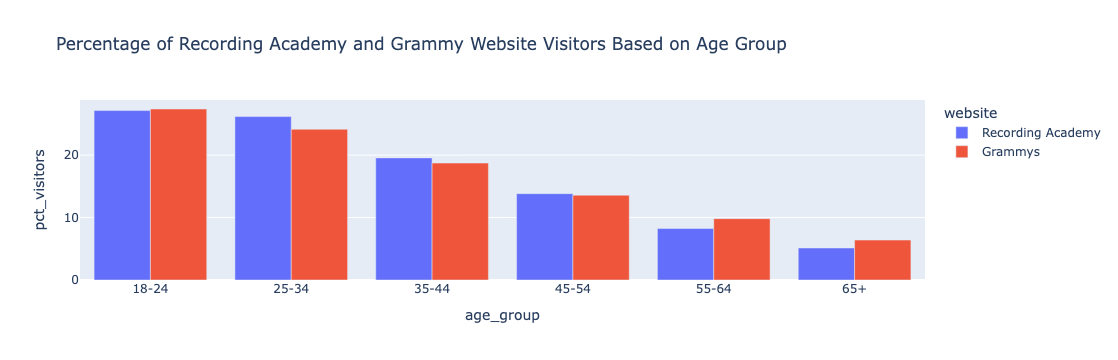

In [56]:
# age_group and pct_visitors bar chart
px.bar(age_df, 
      x = 'age_group', 
      y = 'pct_visitors', 
      title = 'Percentage of Recording Academy and Grammy Website Visitors Based on Age Group', 
      color = 'website', 
      barmode = 'group')

**E.** How does age demographics differ between the 2 websites?

Between the two websites, we can see that the 18-24 age group is the highest percentage of website visitors for both the Recording Academy and the Grammys. The Grammys' 18-24 percent was about 27.4% while the Recording Academy's was 27.1%, which is a small difference. The engagement based on age demographics is relatively the same between both websites, in which the 18-24 and 25-34 age groups make up most of the website vistors and it lowers as age increases. Based off the bar chart, we may think about how both the Recording Academy and Grammy audience is more on the younger side and could be catered more towards that age range to boost engagement.

# **Part 4** - Making a Business Recommendation


## Step 9

Now that I analyzed the engagement metrics before and after the website split, I interpreted my findings and made a recommendation to The Recording Academy team.


**A.** Summarized key findings and suggested a recommendation based on the data: Should The Recording Academy keep the sites separate, merge them back, or consider an alternative approach?


The following are my conclusions based on metrics: 
After the site split, the average_time_on_site metric changed the most after the split. When the websites were combined, the average time on site was around 102.85, the Recording Academy website had an average time of around 128.50 seconds, and the Grammy website had an average time of about 82.99 seconds. From this metric, we can see that the Recording Academy website experienced longer website experience after the split and is higher compared to when both websites were combined, specifically with a difference of about 26 seconds. This suggests that the split helped with more engagement for the Recording Academy website. On the other hand, the Grammy's website average time on site decreased by about 20 seconds when the websites were split, which may indicate how less people are using their Grammy website. 

Additionally, the Bounce Rate metric when the websites were combined was 41.58%. When they split, the Recording Academy had a bounce rate of 33.67% while the Grammy's had a bounce rate of 40.16%. The bounce rate both decreased after the website split, in which the Grammy website experienced a decrease of 1% while the Recording Academy website had a decrease of about 8%. Thus, less users are likely to bounce off the home page of the Recording Academy compared to the Grammy website. We can see that the Recording Academy website experienced the biggest changes among these metrics. The Grammy website did experience a big change in average time on site, but it decreased. In the meeting video, it was explained that the website was split up in which the Grammy website was catered more for the general public and music fans while the Recording Academy was intended for those who work in the industry (producers, professionals, songwriters, etc). This shows how the industry audience may have better user engagement compared to the general music fans. Those in the industry may be more interested in the Recording Academy website since it relates to their work while the general public may not be as engaged on the Grammy website besides during Ceremony night. 

Between the two websites, we can see that the 18-24 age group is the highest percentage of website visitors for both the Recording Academy and the Grammys. The Grammys' 18-24 percent was about 27.4% while the Recording Academy's was 27.1%, which is a small difference. The engagement based on age demographics is relatively the same between both websites, in which the 18-24 and 25-34 age groups make up most of the website vistors and it lowers as age increases. Based off the bar chart, we may think about how both the Recording Academy and Grammy audience is more on the younger side and could be catered more towards that age range to boost engagement. 


**B.** Polished Recommendation

I recommend keeing the Grammy and Recording Academy website separate. The significant increase in average time on site and decrease in bounce rate for the Recording Academy suggest that separating industry-focused content created better engagement for its target audience. However, the decrease in average time on the Grammy website leaves room for improvement in catering to general music fans. Instead of merging the websites again, the Recording Academy should maintain the distinct audiences while strengthening connections between the sites and creating more entertaining and year-round content for the Grammy website. User engagement seems to spike around Grammy nominations and the day of the ceremony, so focusing on year-round engagement is popular. This could be done through, new events, exclusive content from artists, and other new features. Finally, since visitors ages 18-34 make up a large portion of both audiences, website content and experience could be optimized toward this demographic do boost their engagement more. We could also try to increase website engagement of older audiences by promoting more older artists and figuring how it can be easily accessible for them. 

# **Further Analysis** 

How does the Grammys.com website compare to that of their main music award competitor, The American Music Awards (AMA)? The dashboard below is aggregated information about the performance of The AMA website for the months of April, May, and June of 2023.

My goal is to determine how the Grammys website is performing relative to The AMA website. In particular, I will be looking at the device distribution and total visits over the same time span and leveraging information about Visit Duration, Bounce Rate, and Pages / Visit from your work in the core of this project.


![](figs/TheAMAs.png)



The **Total Visits** column is the total number of visitors on the website during the timespan given.
The **Device Distribution** is the percentage share of visitors coming from Desktop users (PCs, Macs, etc.) and Mobile Users (iPhone, Android, etc.).

Visitors on the AMA website are spending on average, 5 mins and 53 seconds on the site and viewing 2.74 pages per visit (aka session). They have a bounce rate of 54.31%

**A.** Loaded in the two files. The `desktop_users.csv` and `mobile_users.csv` files contain the users coming from desktop users and mobile users respectively.

Stored them in variables named `desktop_users` and `mobile_users`

In [57]:
# Load in the data
desktop_users = pd.read_csv('datasets/desktop_users.csv')

mobile_users = pd.read_csv('datasets/mobile_users.csv')

In [58]:
# Preview the desktop_users file
display(desktop_users.head())

,date,segment,visitors
0,2022-02-01,Desktop Traffic,10195
1,2022-02-02,Desktop Traffic,10560
2,2022-02-03,Desktop Traffic,9935
3,2022-02-04,Desktop Traffic,8501
4,2022-02-05,Desktop Traffic,5424


In [59]:
# Preview mobile_users file
display(mobile_users.head())

,date,segment,visitors
0,2022-02-01,Mobile Traffic,23494
1,2022-02-02,Mobile Traffic,20234
2,2022-02-03,Mobile Traffic,22816
3,2022-02-04,Mobile Traffic,18592
4,2022-02-05,Mobile Traffic,13298


**B.** For each dataframe, I changed the name of the `visitors` column so that it says which category they come from. For example, the `desktop_users` dataframe should have a column named `desktop_visitors` instead of `visitors`.

In [60]:
# Change name of the visitors column to indicate which category it comes from
desktop_users.rename(columns = {'visitors': 'desktop_visitors'}, inplace=True)

mobile_users.rename(columns = {'visitors': 'mobile_visitors'}, inplace=True)

In [63]:
# Drop the segment column from each dataframe
desktop_users.drop(columns = ['segment'], inplace = True)

mobile_users.drop(columns = ['segment'], inplace = True)

KeyError: "['segment'] not found in axis"

**Note: Accidentally ran segment column drop cell again, thus the error above.**

**C.** Then, I joined the two dataframes together in a new variable called `segment_df`.

In [67]:
# Join the two dataframes and preview the dataframe
segment_df = pd.concat([desktop_users, mobile_users])

display(segment_df.sample(5))

,date,desktop_visitors,mobile_visitors
282,2022-11-10,NaN,15358.0
490,2023-06-06,6206.0,NaN
199,2022-08-19,4381.0,NaN
201,2022-08-21,3729.0,NaN
385,2023-02-21,NaN,16714.0


In [70]:
segment_df = segment_df.fillna(0)

**D.** Next, I calculated the percentage share of users coming from desktop and mobile on the Grammys website.

New column: `total_visitors` is the addition of `desktop_visitors` and `mobile_visitors`.

In [71]:
# Create total_visitors column
segment_df['total_visitors'] = segment_df['desktop_visitors'] + segment_df['mobile_visitors']

In [79]:
# Filter and calculate the percentage share
# Use an f string to print each percentage to the screen
n_desktop = segment_df[segment_df['date'] >= '2023-04-01']['desktop_visitors'].sum()

n_mobile = segment_df[segment_df['date'] >= '2023-04-01']['mobile_visitors'].sum()

n_total_visitors = n_desktop + n_mobile

perc_desktop = 100 * n_desktop / n_total_visitors 

perc_mobile = 100 * n_mobile / n_total_visitors

print(f'The percentage of mobile visitors is {perc_mobile:.2f}%.')
print(f'The percentage of desktop visitors is {perc_desktop:.2f}%.')

The percentage of mobile visitors is 68.16%.
The percentage of desktop visitors is 31.84%.


**E.** How is the Grammys website performing relative to its competitor? What is the Grammys doing well and what KPIs does it need to improve?

Around 68% of the users of the AMA website use their mobile devices while 32% use their desktop devices, showing how its audience is heavily mobile-focused. To assess the Grammy's website performance relative to the AMA's, we would need to explore its percentage of mobile and desktop visitors. Hypothetically, if the Grammys has a higher percentage of mobile visitors, this is a good sign that the website is reaching users through the most common device. Since the percentage of mobile users is higher, the Grammys should try to make sure their website is easily accessible on mobile devices. 

Furthermore, the Grammys should focus on improving KPIs that boost engagement such as time on site, bounce rate, and pages per session. When the website split occurred, the Grammy website had a decrease in average time on site, showing that users are less engaged on its website. Improving year-round content and the mobile user experience could help encourage visitors to explore the website more. 